# EDA: meteorology vs wind generation

Relationship between Open-Meteo variables and ESIOS wind generation, by province (`data/processed/dataset.csv`).

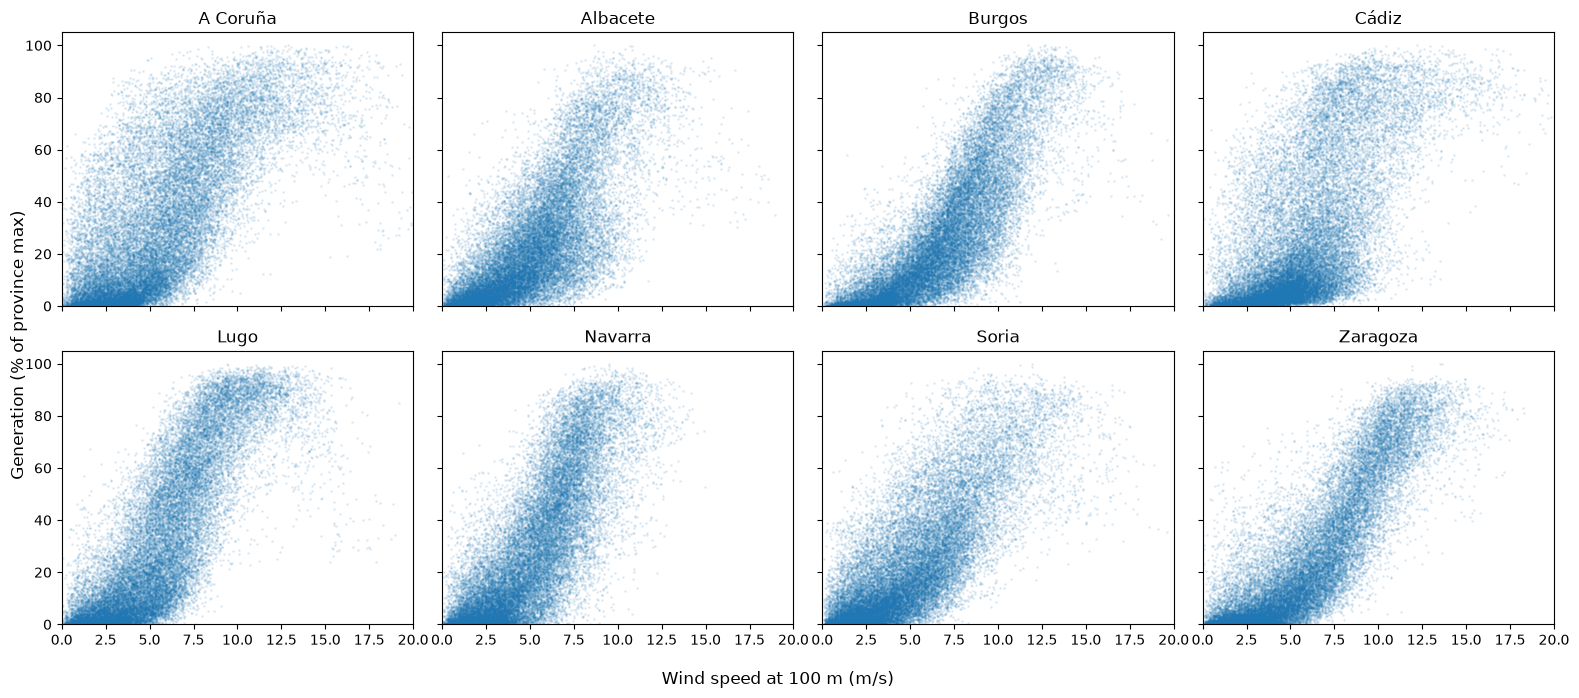

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/dataset.csv")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)

# Generation as % of each province's max, so curves are comparable
max_by_province = df.groupby("provincia")["generacion_mw"].transform("max")
df["gen_pct"] = df["generacion_mw"] / max_by_province * 100

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)

for (provincia, grupo), ax in zip(df.groupby("provincia"), axes.flatten()):
    ax.scatter(grupo["wind_speed_100m"], grupo["gen_pct"], s=1, alpha=0.1)
    ax.set_title(provincia)

ax.set_xlim(0, 20)
ax.set_ylim(0, 105)

fig.supxlabel("Wind speed at 100 m (m/s)")
fig.supylabel("Generation (% of province max)")

plt.tight_layout()
plt.show()

### Power curve: conclusions

- The power curve shape (cut-in ~4 m/s, steep rise, plateau from ~12 m/s) is clear in
  **Burgos, Lugo and Zaragoza**.
- **Cádiz and A Coruña** show much more scatter: similar measured wind speeds produce
  anything from 0 to 100% of max generation. Most likely the single Open-Meteo point per
  province (the provincial capital) does not represent where the wind farms actually are
  (e.g. Cádiz farms are mainly around Tarifa, ~80 km away).
- Possible improvement: use several weather points per province, located at the wind farms.